# Life Expectancy Prediction Model

In [1]:
#importing required packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,KFold
from sklearn.metrics import root_mean_squared_error
from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor,export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
import xgboost as xgb

from IPython import display
sns.set_theme(style="whitegrid")

## Importing the Dataset and Preprocessing

In [2]:
#Import 
df = pd.read_csv("Life Expectancy Data.csv")
print(f"The shape of the dataset: {df.shape}")
df.head()

The shape of the dataset: (2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


Handling missing data

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

- We can see most of features have missing values. We have 2 categorical features and 20 numerical features. I will inspect more precisely to know which features are missing. 
- I also see some column names are in inconsistant format. 
I will do two things here.
1) I will re-format columns into a consistant format. 
2) I will find out which columns have missing values. 
- If my target column - life_expectancy has missing values,
I will drop out all rows along with that as my using method is Supervised Regression and therefore, I need to have target vaules. 
- If other features have missing values, I will try to fill with 3 diff methods (most frequent value, NA, mean, 0).

In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ","_")

In [5]:
miss_features = pd.DataFrame({"Total Missing Counts":df.isna().sum().sort_values(ascending = False),})
miss_features[miss_features['Total Missing Counts']> 0]
    

,Total Missing Counts
population,652
hepatitis_b,553
gdp,448
total_expenditure,226
alcohol,194
income_composition_of_resources,167
schooling,163
thinness_5-9_years,34
thinness__1-19_years,34
bmi,34


I notice one thing --> "str" features are not in the miss_features table.

That means categorical_features do not have missing values.

In [6]:
#As my target life_expectancy has missing values, I will drop them. 
df.dropna(subset=["life_expectancy"],inplace=True)

#Dataframe shape after dropping 10 rows
df.shape

(2928, 22)

# Splitting the dataset
**Train:** Train the diff model (60%)

**Val:** Finding the best parameters (20%)

**Test:** Keeping this data for the final best model validation (Models haven't seen this part of data before.) (20%)

In [7]:
#Splitting Categorical features and Numerical features
categorical_features = list(df.dtypes[df.dtypes == "str"].index)
numerical_features = list(df.dtypes[(df.dtypes == "int") | (df.dtypes == "float64")].index)

In [8]:
#Removing the target feature from the list
del numerical_features[1]

In [9]:
full_train,test = train_test_split(df,test_size=0.2,random_state=42)
train,val = train_test_split(full_train,test_size=0.2,random_state=42)

In [10]:
df.shape[0] == (test+train+val).shape[0]

True

In [11]:
#to avoid overwritting the original split datasets, I copied datasets.
train_data = train.copy()
val_data = val.copy()

In [12]:
target = 'life_expectancy'
X_train = train_data.drop(columns=[target]).reset_index(drop=True)
y_train = train_data[[target]].reset_index(drop=True)

X_val = val_data.drop(columns=[target]).reset_index(drop=True)
y_val = val_data[[target]].reset_index(drop=True)

In [12]:
X_train.head()

,country,year,status,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,bmi,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness__1-19_years,thinness_5-9_years,income_composition_of_resources,schooling
0,Swaziland,2004,Developing,69.0,3,5.78,37.438577,93.0,0,27.4,...,88.0,5.88,86.0,50.3,2529.633557,19553.0,7.7,7.9,0.492,9.4
1,Fiji,2009,Developing,23.0,0,2.31,60.650684,99.0,1,58.0,...,99.0,4.26,99.0,0.1,3369.482470,851967.0,4.0,3.7,0.704,14.5
2,Turkmenistan,2013,Developing,228.0,7,2.93,63.748112,98.0,0,46.7,...,98.0,2.12,98.0,0.1,734.425250,5366277.0,3.2,3.3,0.678,10.7
3,Russian Federation,2004,Developing,321.0,19,11.50,46.515595,96.0,2444,55.0,...,98.0,5.19,97.0,0.3,412.372294,1446754.0,2.5,2.8,0.741,13.6
4,Gabon,2006,Developing,288.0,2,8.01,40.537198,52.0,90,31.4,...,44.0,2.88,45.0,10.7,727.777345,1444844.0,7.1,6.9,0.646,12.4


#Choosing the most suitable {fillna} value by testing {Diff values} with a base regression model

We have two possible fillna values for numerical features: 0 and mean 

1. Testing with "0".

In [14]:
#Building Base model 
base_0 = LinearRegression()

#building based_dv 
base_dv_0 = DictVectorizer(sparse=False)

In [15]:
X_train_0 = X_train.copy()
X_val_0 = X_val.copy()

In [16]:
X_train_0 = X_train_0.fillna(0)
X_val_0 =X_val_0.fillna(0)

In [17]:
X_train_0 = base_dv_0.fit_transform(X_train_0.to_dict(orient="records"))
X_val_0 = base_dv_0.transform(X_val_0.to_dict(orient="records"))

In [18]:
base_0.fit(X_train_0,y_train)
predictions_0 = base_0.predict(X_val_0)
error_0 = root_mean_squared_error(y_val,predictions_0)
print("the error of base model with fillna 0: %.3f" % error_0)

the error of base model with fillna 0: 6.364


2. Testing with "mean".

In [19]:
#Building Base model 
base_mean = LinearRegression()

#building based_dv 
base_dv_mean = DictVectorizer(sparse=False)

In [20]:
X_train_mean = X_train.copy()
X_val_mean = X_val.copy()

In [21]:
for feature in numerical_features:
    mean = df[feature].mean()
    X_train_mean[feature] = X_train_mean[feature].fillna(mean)
    X_val_mean[feature] = X_val_mean[feature].fillna(mean)

In [22]:
X_train_mean = base_dv_mean.fit_transform(X_train_mean.to_dict(orient="records"))
X_val_mean = base_dv_mean.transform(X_val_mean.to_dict(orient="records"))

In [23]:
base_mean.fit(X_train_mean,y_train)
predictions_mean = base_mean.predict(X_val_mean)
error_mean = root_mean_squared_error(y_val,predictions_mean)
print("the error of base model with fillna mean: %.3f" % error_mean)

the error of base model with fillna mean: 6.391


In [24]:
error_0<error_mean

True

As filling with "0" gives the smallest RMSE, I will choose fillna"0" method to handle missing data.

In [15]:
X_train = X_train.fillna(0)
X_val =X_val.fillna(0)

In [26]:
# for feature in numerical_features:
#     mean = df[feature].mean()
#     X_train[feature] = X_train[feature].fillna(mean)
#     X_val[feature] = X_val[feature].fillna(mean)
#     X_test[feature] = X_test[feature].fillna(mean)
    

#     print("Feature: %34s  mean: %.3f" % (feature, mean))

# Inspecting Correlations between Features and Target 

In [122]:
corr_df = pd.concat([X_train[numerical_features],y_train],axis = 1)

In [123]:
corr = corr_df.corr()["life_expectancy"].sort_values(ascending = False)

In [124]:
corr_values = pd.DataFrame({"Features":corr.index,"Correlation Values with Target":
                    corr.values})
corr_values

,Features,Correlation Values with Target
0,life_expectancy,1.000000
1,income_composition_of_resources,0.582331
2,bmi,0.578406
3,schooling,0.555938
4,diphtheria,0.474014
5,polio,0.461409
6,gdp,0.427186
7,percentage_expenditure,0.383089
8,alcohol,0.366027
9,hepatitis_b,0.234798


I find out some features have strong correlation with target value which means their corr score is greater than 0.5 regardless of positivity and negativity.

In [125]:
corr_greaterthan_0_5 = corr_values[(abs(corr_values["Correlation Values with Target"])>= 0.5) 
                        & (abs(corr_values["Correlation Values with Target"])!=1)]
corr_greaterthan_0_5

,Features,Correlation Values with Target
1,income_composition_of_resources,0.582331
2,bmi,0.578406
3,schooling,0.555938
18,hiv/aids,-0.570746
19,adult_mortality,-0.695454


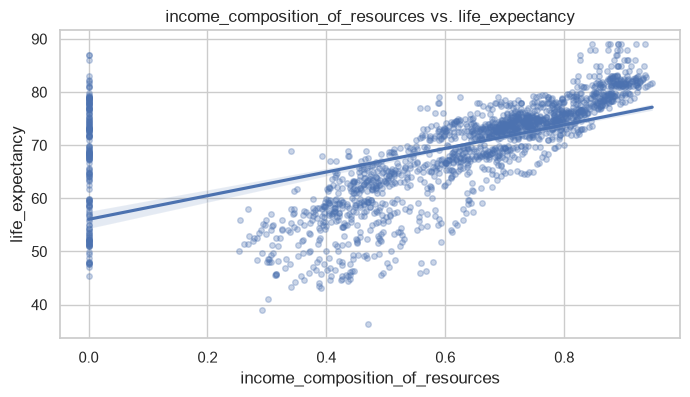

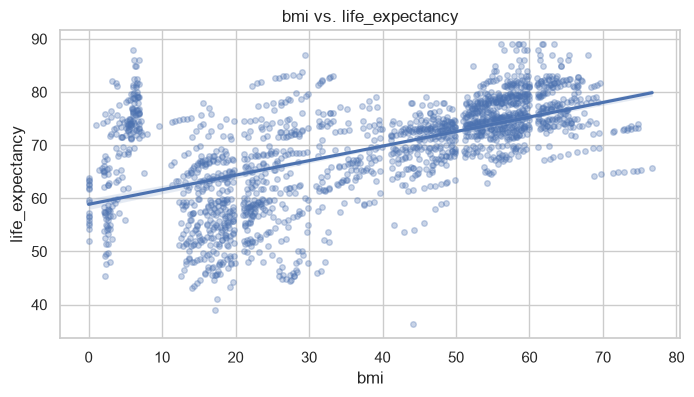

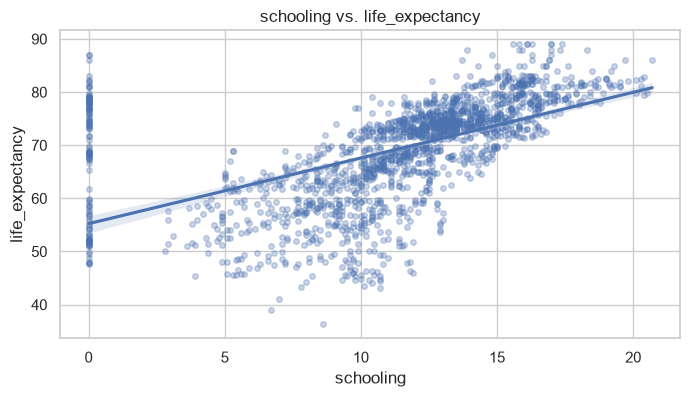

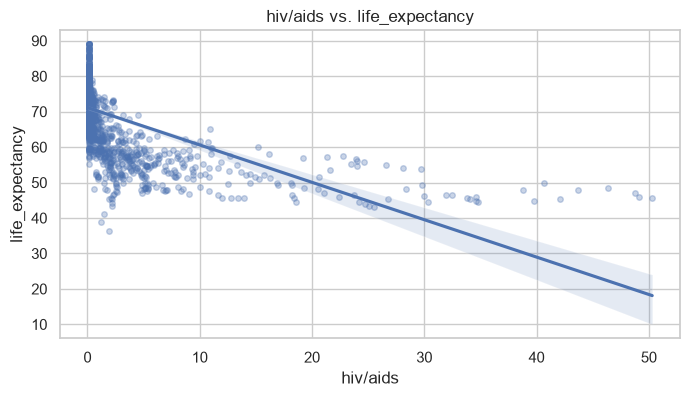

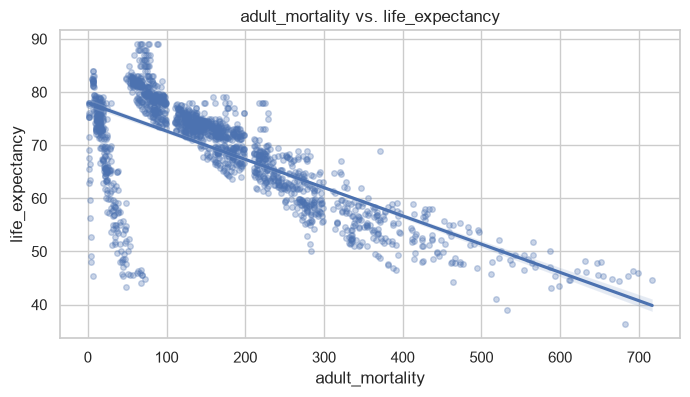

In [126]:
for feature in corr_greaterthan_0_5["Features"]:
    target = "life_expectancy"
    plt.figure(figsize = (8,4))
    sns.regplot(data=corr_df,x=corr_df[feature],y=corr_df[target],
                scatter_kws={
                    "alpha":0.3,
                    "s":16
                })
    plt.title(f"{feature} vs. {target}")
    plt.show();

#

# Encoding Categorical Features Using DictVectorizer()

In [17]:
#Building DictVectorizer Transformer
dv = DictVectorizer(sparse=False)

#transforming my three datasets into dicts
X_train_dicts = X_train.to_dict(orient="records")
X_val_dicts = X_val.to_dict(orient="records")


#Encoding Datasets
train_encod = dv.fit_transform(X_train_dicts)
val_encod = dv.transform(X_val_dicts)

# **1st Model:** Linear Regression Model

In [127]:
#Bilding LinearRegression Model
linear_reg = LinearRegression()
linear_reg.fit(train_encod,y_train)
linear_predictions = linear_reg.predict(val_encod)
linear_rmse = root_mean_squared_error(y_val,linear_predictions)
print("RMSE of linear Regression Model: %.4f" % linear_rmse)

RMSE of linear Regression Model: 6.3643


# **2nd Model:** DecisionTreeRegressor Model

1. Building DecisionTreeRegressor

In [128]:
#Default Model
decision_default_regressor = DecisionTreeRegressor(random_state=0)

decision_default_regressor.fit(train_encod,y_train)
decision_default_predictions = decision_default_regressor.predict(val_encod)
decision_default_rmse = root_mean_squared_error(y_val,decision_default_predictions)
print("RMSE of  DecisionTreeRegressor Model with default parameters: %.4f" % decision_default_rmse)

decision_default_rmse_train = root_mean_squared_error(y_train,decision_default_regressor.predict(train_encod))
print("RMSE of  DecisionTreeRegressor Model with default parameters (RMSE for train dataset0): %.4f" 
      % decision_default_rmse_train)

RMSE of  DecisionTreeRegressor Model with default parameters: 2.7016
RMSE of  DecisionTreeRegressor Model with default parameters (RMSE for train dataset0): 0.0000


**Analysis:** We can see that our model suffers from overfitting. Although it has 100% accuracy on train dataset, it doesn't perform will on val dataset. That's the sign of overfitting.

2) Parameters Tuning for DecisionTreeRegressor Model

In [129]:
#max_depth tuning
depth_scores = []
for depth in [1,2,3,4,5,6,10,15,20,21,23,25,26,None]:
    decision_depth_regressor = DecisionTreeRegressor(max_depth=depth,random_state=0)

    decision_depth_regressor.fit(train_encod,y_train)
    decision_depth_predictions = decision_depth_regressor.predict(val_encod)
    decision_depth_rmse = root_mean_squared_error(y_val,decision_depth_predictions)

    decision_depth_rmse_train = root_mean_squared_error(y_train,
                                                          decision_depth_regressor.predict(train_encod))
    depth_scores.append((depth,decision_depth_rmse,decision_depth_rmse_train))

In [130]:
depth_df = pd.DataFrame(depth_scores,columns=['max_depth','RMSE',"RMSE_train"]).sort_values(by='RMSE')
depth_df.head(3)

,max_depth,RMSE,RMSE_train
7,15.0,2.693517,0.375274
11,25.0,2.700375,0.002311
12,26.0,2.701575,0.000000


I choose the first 2 max_depths --> [15,25] for the rest tuning operations.

In [131]:
#min_samples_leaf tuning 
leaf_scores = []
for depth in [15,25]:
    for leaf in range(1,200,5):
        decision_leaf_regressor = DecisionTreeRegressor(max_depth=depth,min_samples_leaf=leaf,random_state=0)

        decision_leaf_regressor.fit(train_encod,y_train)
        decision_leaf_predictions = decision_leaf_regressor.predict(val_encod)
        decision_leaf_rmse = root_mean_squared_error(y_val,decision_leaf_predictions)

        decision_leaf_rmse_train = root_mean_squared_error(y_train,
                                                            decision_leaf_regressor.predict(train_encod))
        leaf_scores.append((depth,leaf,decision_leaf_rmse,decision_leaf_rmse_train))

In [132]:
leaf_df = pd.DataFrame(leaf_scores,columns=['max_depth','min_samples_leaf','RMSE',"RMSE_train"]).sort_values(by='RMSE')
leaf_df.head(3)

,max_depth,min_samples_leaf,RMSE,RMSE_train
1,15,6,2.590323,1.410177
41,25,6,2.590323,1.410177
0,15,1,2.693517,0.375274


**Best Parameters:** Based on the above table, I choose max_depth = 15 and min_samples_leaf = 6 for DecisionTreeRegressor.

In [133]:
#Tuned DecisionTreeRegressor Model
decision_regressor = DecisionTreeRegressor(max_depth = 15, min_samples_leaf=6, random_state=0)

decision_regressor.fit(train_encod,y_train)
decision_predictions = decision_regressor.predict(val_encod)
decision_rmse = root_mean_squared_error(y_val,decision_predictions)
print("RMSE of  DecisionTreeRegressor Model with tuned parameters: %.4f" % decision_rmse)

RMSE of  DecisionTreeRegressor Model with tuned parameters: 2.5903


# **3rd Model:** RandomForestRegressor Model

In [134]:
y_train = y_train.values.ravel()
y_val = y_val.values.ravel()

In [135]:
#randomforestregressor model with default
regressor_default = RandomForestRegressor(random_state=0)

regressor_default.fit(train_encod,y_train)
regressor_default_predictions = regressor_default.predict(val_encod)
regressor_default_rmse = root_mean_squared_error(y_val,regressor_default_predictions)

print("RMSE RandomForestRegressor Model with default parameter: %.4f" % regressor_default_rmse)
print("RMSE RandomForestRegressor Model with default parameter on train data: %.4f" 
      % root_mean_squared_error(y_train,regressor_default.predict(train_encod)))

RMSE RandomForestRegressor Model with default parameter: 2.0182
RMSE RandomForestRegressor Model with default parameter on train data: 0.6825


Model performance is quite good with default parameters. However, I will train 3 parameters for this model for the better Regression model.
1) n_estimator
2) max_depth
3) min_samples_leaf

In [136]:
#max_depth and n_estimator tuning
scores_d_n = []
for depth in [1,2,3,4,5,6,10,15,20,21,23,25,26,None]:
    for n in range(10,202,10):
        regressor_depth = RandomForestRegressor(
            random_state=0,
            max_depth=depth,
            n_estimators=n,
            verbose = 0,
            n_jobs=-1)

        regressor_depth.fit(train_encod,y_train)
        regressor_depth_predictions = regressor_depth.predict(val_encod)
        regressor_depth_rmse = root_mean_squared_error(y_val,regressor_depth_predictions)

        scores_d_n.append((depth,n,regressor_depth_rmse))

In [137]:
scores_d_n_df = pd.DataFrame(scores_d_n,columns=['max_depth','n_estimator','RMSE']).sort_values(by='RMSE')
scores_d_n_df.head(3)

,max_depth,n_estimator,RMSE
249,26.0,100,2.008015
248,26.0,90,2.008059
168,20.0,90,2.008530


Based on the result table, I chose [20,26] for max_depth parameter and [90,100] for n_estimator for min_samples_leaf parameter tuning.

In [138]:
#min_samples_leaf tuning
scores_f_n = []
for depth in [20,26]:
    for n in [90,100]:
        for leaf in range(1,200,5):
            regressor_leaf = RandomForestRegressor(
                random_state=0,
                max_depth=depth,
                n_estimators=n,
                min_samples_leaf=leaf,
                verbose = 0,
                n_jobs=-1)

            regressor_leaf.fit(train_encod,y_train)
            regressor_leaf_predictions = regressor_leaf.predict(val_encod)
            regressor_leaf_rmse = root_mean_squared_error(y_val,regressor_leaf_predictions)

            scores_f_n.append((depth,n,leaf,regressor_leaf_rmse))

In [139]:
scores_f_n_df = pd.DataFrame(scores_f_n,columns=['max_depth','n_estimator','min_samples_leaf','RMSE']).sort_values(by='RMSE')
scores_f_n_df.head(3)

,max_depth,n_estimator,min_samples_leaf,RMSE
120,26,100,1,2.008015
80,26,90,1,2.008059
0,20,90,1,2.008530


**Final Decision:** max_depth = 26, n_estimator = 100, min_samples_leaf = 1

In [140]:
#randomforestregressor model with selected parameter values
regressor_tuned = RandomForestRegressor(
                random_state=0,
                max_depth=26,
                n_estimators=100,
                min_samples_leaf=1,
                verbose = 0,
                n_jobs=-1)

regressor_tuned.fit(train_encod,y_train)
regressor_tuned_predictions = regressor_tuned.predict(val_encod)
regressor_tuned_rmse = root_mean_squared_error(y_val,regressor_tuned_predictions)

print("RMSE RandomForestRegressor Model with tuned parameter: %.4f" % regressor_tuned_rmse)

RMSE RandomForestRegressor Model with tuned parameter: 2.0080


# **4th Model:** xgboost Model (Gradient Boosting)

In [18]:
#I need to create DMatrix to use xgboost
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(train_encod,label=y_train,feature_names=features)
dval = xgb.DMatrix(val_encod,label=y_val,feature_names=features)

In [19]:
#create watchlist to track model training process
watchlist = [(dtrain,"train"),(dval,"val")]

In [21]:
def output_xgb (output):
    scores = []
    for line in output.stdout.strip().split('\n'):
        iter,train_se,val_se = line.split('\t')
        iter = int(iter.strip('[]'))
        train_se = float(train_se.split(':')[1])
        val_se = float(val_se.split(':')[1])

        scores.append((iter,train_se,val_se))
    columns = ['Iterations','Train_squarederror','Val_squarederror']
    scores_df = pd.DataFrame(scores,columns=columns).sort_values(by='Val_squarederror')

    return scores_df

1) Eta Tuning

I tuned eta with these values ['eta=0.9', 'eta=0.1', 'eta=0.5', 'eta=0.05', 'eta=0.7', 'eta=1', 'eta=0.01'].

In [57]:
xgb_results_eta = {}

In [70]:
%%capture output

xgb_params = {
    'eta': 0.7,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params,dtrain,num_boost_round = 251,verbose_eval=10,evals = watchlist)

In [71]:
key = 'eta=%s'%(xgb_params['eta'])
xgb_results_eta[key] = output_xgb(output)

In [72]:
xgb_results_eta.keys()

dict_keys(['eta=0.9', 'eta=1', 'eta=0.1', 'eta=0.01', 'eta=0.5', 'eta=0.05', 'eta=0.7'])

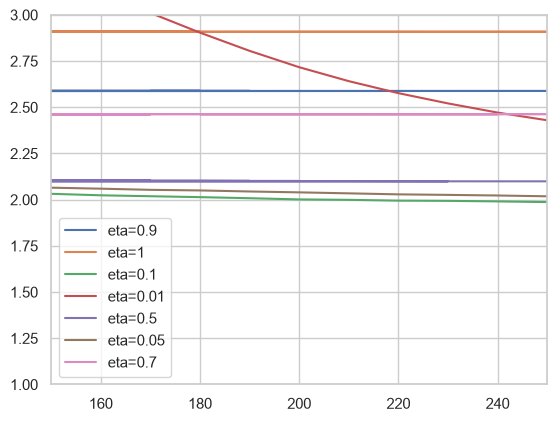

In [73]:
for key,scores_df in xgb_results_eta.items():
    plt.plot(scores_df.Iterations,scores_df.Val_squarederror, label=key)
    plt.xlim(150,250)
    plt.ylim(1,3)
plt.legend()

I choose eta = 0.1 as it becomes stable at the lowest point more smoothly.

2) Max_depth tuning

I tuned max_depth with these diff values ['max_depth=6','max_depth=3', 'max_depth=7', 'max_depth=8', 'max_depth=9', 'max_depth=10', 'max_depth=15', 'max_depth=20', 'max_depth=50', 'max_depth=100'].

In [74]:
xgb_results_depth = {}

In [94]:
%%capture output
xgb_params = {
    'eta': 0.1, 
    'max_depth': 100,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params,dtrain,num_boost_round = 251,verbose_eval=10,evals = watchlist)

In [95]:
key = 'max_depth=%s'%(xgb_params['max_depth'])
xgb_results_depth[key] = output_xgb(output)

In [96]:
xgb_results_depth.keys()

dict_keys(['max_depth=3', 'max_depth=6', 'max_depth=7', 'max_depth=8', 'max_depth=9', 'max_depth=10', 'max_depth=15', 'max_depth=20', 'max_depth=50', 'max_depth=100'])

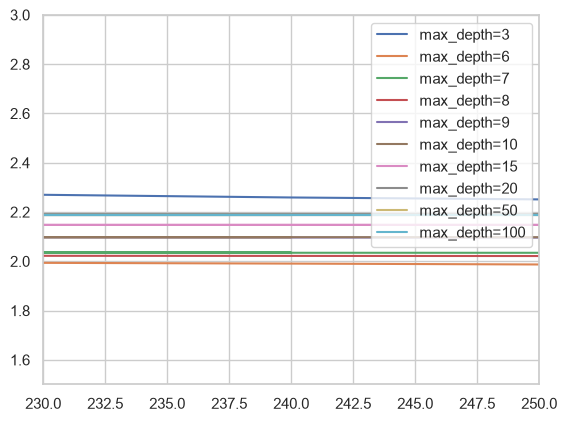

In [97]:
for key,scores_df in xgb_results_depth.items():
    plt.plot(scores_df.Iterations,scores_df.Val_squarederror, label=key)
    plt.ylim(1.5,3)
    plt.xlim(230,250)
plt.legend()

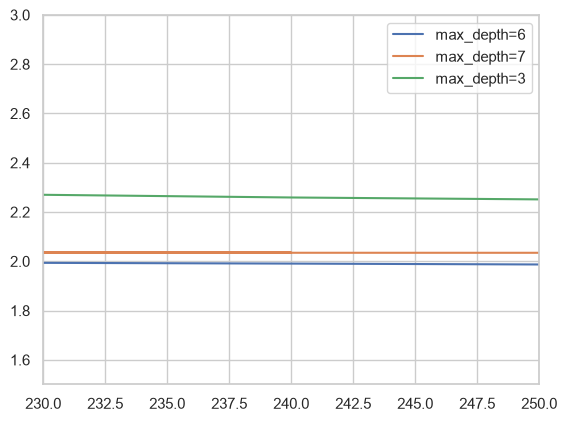

In [99]:
max_depth = ['max_depth=6', 'max_depth=7', 'max_depth=3']
for depth in max_depth:
    df_scores = xgb_results_depth[depth]
    plt.plot(df_scores.Iterations,df_scores.Val_squarederror, label=depth)
    plt.ylim(1.5,3)
    plt.xlim(230,250)
plt.legend();

#I chose max_depth = 6 based on the above graph.

3) min_child_weight Tuning

I tuned min_child_weight with dict_keys(['min_child_weight=30', 'min_child_weight=5', 'min_child_weight=1', 'min_child_weight=10', 'min_child_weight=15', 'min_child_weight=20']).

In [100]:
xgb_results_child = {}

In [113]:
%%capture output
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 30,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

xgb_model = xgb.train(xgb_params,dtrain,num_boost_round = 251,verbose_eval=10,evals = watchlist)

In [114]:
key = 'min_child_weight=%s'%(xgb_params['min_child_weight'])
xgb_results_child[key] = output_xgb(output)

In [115]:
xgb_results_child.keys()

dict_keys(['min_child_weight=1', 'min_child_weight=5', 'min_child_weight=10', 'min_child_weight=15', 'min_child_weight=20', 'min_child_weight=30'])

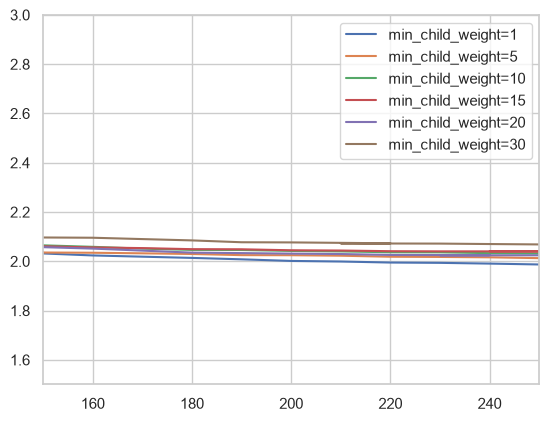

In [116]:
for key,scores_df in xgb_results_child.items():
    plt.plot(scores_df.Iterations,scores_df.Val_squarederror, label=key)
    plt.ylim(1.5,3)
    plt.xlim(150,250)
plt.legend()

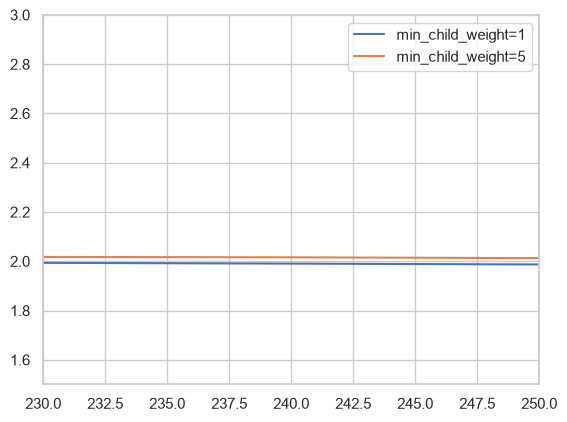

In [117]:
min_child_weight = ['min_child_weight=1','min_child_weight=5']
for depth in min_child_weight:
    df_scores = xgb_results_child[depth]
    plt.plot(df_scores.Iterations,df_scores.Val_squarederror, label=depth)
    plt.ylim(1.5,3)
    plt.xlim(230,250)
plt.legend();

**Final Decision:** I will use eta = 0.1, max_depth = 6 and min_child_weight = 1 for my xgb model.

In [120]:
xgb_params_tuned = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

xgb_tuned = xgb.train(xgb_params_tuned,dtrain,num_boost_round = 251,verbose_eval=10,evals = watchlist)

[0]	train-rmse:8.72949	val-rmse:8.67349
[10]	train-rmse:3.60789	val-rmse:3.97683
[20]	train-rmse:1.89387	val-rmse:2.63089
[30]	train-rmse:1.33635	val-rmse:2.25679
[40]	train-rmse:1.11978	val-rmse:2.16582
[50]	train-rmse:1.02707	val-rmse:2.12835
[60]	train-rmse:0.98173	val-rmse:2.10486
[70]	train-rmse:0.95229	val-rmse:2.08909
[80]	train-rmse:0.92472	val-rmse:2.08270
[90]	train-rmse:0.90260	val-rmse:2.07108
[100]	train-rmse:0.87592	val-rmse:2.06357
[110]	train-rmse:0.84934	val-rmse:2.05840
[120]	train-rmse:0.83195	val-rmse:2.04979
[130]	train-rmse:0.81143	val-rmse:2.04358
[140]	train-rmse:0.78963	val-rmse:2.03643
[150]	train-rmse:0.77474	val-rmse:2.03169
[160]	train-rmse:0.75549	val-rmse:2.02363
[170]	train-rmse:0.74510	val-rmse:2.01859
[180]	train-rmse:0.72370	val-rmse:2.01364
[190]	train-rmse:0.70369	val-rmse:2.00792
[200]	train-rmse:0.68874	val-rmse:2.00135
[210]	train-rmse:0.67345	val-rmse:1.99904
[220]	train-rmse:0.65567	val-rmse:1.99480
[230]	train-rmse:0.63804	val-rmse:1.99357
[24

In [121]:
xgb_prediction = xgb_tuned.predict(dval)
xgb_rmse = root_mean_squared_error(y_val,xgb_prediction)
print("RMSE XGB Model with tuned parameter: %.4f" % xgb_rmse)

RMSE XGB Model with tuned parameter: 1.9870


# Collecting all models' performance on Val dataset

In [141]:
final_collect = {}
final_collect["Linear Regression RMSE"] = linear_rmse
final_collect["Decision Tree Regressor RMSE "] = decision_rmse
final_collect["Random Forest Regressor RMSE"] = regressor_tuned_rmse
final_collect["XGB RMSE"] = xgb_rmse

In [142]:
final_collect

{'Linear Regression RMSE': 6.364314531103309,
 'Decision Tree Regressor RMSE ': 2.5903234175212946,
 'Random Forest Regressor RMSE': 2.0080151102216988,
 'XGB RMSE': 1.986995816230774}

**Final Model:** I choose XGB model to train my whole dataset as it gives the smallest RMSE.

# Final Training 

# Using Cross-validation on Full_train Dataset

In [27]:
from tqdm.auto import tqdm
#Building DictVectorizer Transformer
dv_fold = DictVectorizer(sparse=False)

xgb_params_final = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

kfold = KFold(n_splits=5, shuffle=True, random_state=2)
scores_fold = {}
for i,(train_idx,val_idx) in tqdm(enumerate(kfold.split(full_train))):
    fold_train = full_train.iloc[train_idx].reset_index(drop=True)
    fold_val = full_train.iloc[val_idx].reset_index(drop=True)

    X_fold_train = fold_train.drop(columns=[target]).fillna(0)
    y_fold_train = fold_train[[target]].values.ravel()

    X_fold_val = fold_val.drop(columns=[target]).fillna(0)
    y_fold_val = fold_val[[target]].values.ravel()

    fold_train_dicts = X_fold_train.to_dict(orient="records")
    fold_val_dicts = X_fold_val.to_dict(orient="records")

    fold_train_encod = dv_fold.fit_transform(fold_train_dicts)
    fold_val_encod = dv_fold.transform(fold_val_dicts)

    fold_features = list(dv_fold.get_feature_names_out())
    dfold_train = xgb.DMatrix(fold_train_encod,label=y_fold_train,feature_names=fold_features)
    dfold_val = xgb.DMatrix(fold_val_encod,label = y_fold_val,feature_names=fold_features)

    xgb_fold_model = xgb.train(xgb_params_final,dfold_train,num_boost_round = 251)

    xgb_fold_prediction = xgb_fold_model.predict(dfold_val)
    xgb_fold_rmse = root_mean_squared_error(y_fold_val,xgb_fold_prediction)
    scores_fold[f"fold {i+1}"] = xgb_fold_rmse

scores_fold

0it [00:00, ?it/s]

{'fold 1': 1.6319103839324012,
 'fold 2': 1.8324476112886519,
 'fold 3': 1.992046107029333,
 'fold 4': 1.9356755192363855,
 'fold 5': 1.8411576696434606}

In [28]:
score_list = list(scores_fold.values())
print("%.3f +- %.3f" % (np.mean(score_list),np.std(score_list)))

1.847 +- 0.123


# Preparing dataset for my choice XGB Model

In [29]:
X_full_train = full_train.drop(columns=[target]).reset_index(drop=True)
y_full_train = full_train[[target]].values.ravel()

X_test = test.drop(columns=[target]).reset_index(drop=True)
y_test = test[[target]].values.ravel()

#filling "0" in missing values
X_full_train = X_full_train.fillna(0)
X_test = X_test.fillna(0)

In [30]:
#Building DictVectorizer Transformer
dv_final = DictVectorizer(sparse=False)
X_full_dicts = X_full_train.to_dict(orient="records")
X_test_dicts = X_test.to_dict(orient="records")

train_encod = dv_final.fit_transform(X_full_dicts)
test_encod = dv_final.transform(X_test_dicts)

features = list(dv_final.get_feature_names_out())
dfull_train = xgb.DMatrix(train_encod,label = y_full_train,feature_names=features)
dtest = xgb.DMatrix(test_encod,feature_names=features)

#xgb_final_model
xgb_final_model = xgb.train(xgb_params_final,dfull_train,num_boost_round = 251)

#testing model on test dataset
xgb_test_prediction = xgb_final_model.predict(dtest)
xgb_test_rmse = root_mean_squared_error(y_test,xgb_test_prediction)
print("RMSE XGB of Model : %.4f" % xgb_test_rmse)

RMSE XGB of Model : 1.6596


***Conclusion:*** My final model is stable and good because its RMSE is in the acceptable range when compared to cross-validation result. My final model performance is even better than the mean value of cross-val.

In [31]:
sample_data = X_full_dicts[0]
sample_data_tran = dv_final.transform(sample_data)

In [24]:
sample_data

{'country': 'Serbia',
 'year': 2012,
 'status': 'Developing',
 'adult_mortality': 126.0,
 'infant_deaths': 1,
 'alcohol': 9.38,
 'percentage_expenditure': 742.5109709,
 'hepatitis_b': 97.0,
 'measles': 0,
 'bmi': 58.3,
 'under-five_deaths': 1,
 'polio': 93.0,
 'total_expenditure': 9.89,
 'diphtheria': 91.0,
 'hiv/aids': 0.1,
 'gdp': 5659.3824,
 'population': 719977.0,
 'thinness__1-19_years': 2.1,
 'thinness_5-9_years': 2.1,
 'income_composition_of_resources': 0.767,
 'schooling': 14.0}

In [25]:
full_train.head(1)

,country,year,status,life_expectancy,adult_mortality,infant_deaths,alcohol,percentage_expenditure,hepatitis_b,measles,...,polio,total_expenditure,diphtheria,hiv/aids,gdp,population,thinness__1-19_years,thinness_5-9_years,income_composition_of_resources,schooling
2268,Serbia,2012,Developing,74.9,126.0,1,9.38,742.510971,97.0,0,...,93.0,9.89,91.0,0.1,5659.3824,719977.0,2.1,2.1,0.767,14.0


In [26]:
predicted_value = xgb_final_model.predict(xgb.DMatrix(sample_data_tran,feature_names=features))
true_value = float(y_full_train[0])
print(f"Predicted Value: {predicted_value[0]}")
print(f"True Value: {true_value}")

Predicted Value: 75.1048355102539
True Value: 74.9
